In [17]:
from pathlib import Path
import json
import random

import pandas as pd
import matplotlib.pyplot as plt
from datasets import get_dataset_config_names, load_dataset

In [ ]:
DATASET_NAME = "ceval/ceval-exam"

REPO_ROOT = Path("/scratch/workspace/emma/standard-project-m2-mystery-machine")
OUTPUT_DIR = REPO_ROOT / "multilingual" / "data" / "preprocessed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ALL_PATH = OUTPUT_DIR / "ceval_chinese_all.jsonl"

SPLITS_TO_LOAD = ["dev", "val", "test"]
VALID_ANSWERS = {"A", "B", "C", "D"}

RANDOM_SEED = 42

In [19]:
SUBJECT_TO_CATEGORY = {
    # STEM
    "computer_network": "STEM",
    "operating_system": "STEM",
    "computer_architecture": "STEM",
    "college_programming": "STEM",
    "college_physics": "STEM",
    "college_chemistry": "STEM",
    "advanced_mathematics": "STEM",
    "probability_and_statistics": "STEM",
    "discrete_mathematics": "STEM",
    "electrical_engineer": "STEM",
    "metrology_engineer": "STEM",
    "high_school_mathematics": "STEM",
    "high_school_physics": "STEM",
    "high_school_chemistry": "STEM",
    "high_school_biology": "STEM",
    "middle_school_mathematics": "STEM",
    "middle_school_biology": "STEM",
    "middle_school_physics": "STEM",
    "middle_school_chemistry": "STEM",
    "plant_protection": "STEM",
    "environmental_impact_assessment_engineer": "STEM",

    # Humanities
    "chinese_language_and_literature": "Humanities",
    "high_school_chinese": "Humanities",
    "modern_chinese_history": "Humanities",
    "high_school_history": "Humanities",
    "middle_school_history": "Humanities",
    "art_studies": "Humanities",
    "logic": "Humanities",

    # Social Science
    "college_economics": "Social Science",
    "marxism": "Social Science",
    "mao_zedong_thought": "Social Science",
    "education_science": "Social Science",
    "teacher_qualification": "Social Science",
    "high_school_politics": "Social Science",
    "middle_school_politics": "Social Science",
    "high_school_geography": "Social Science",
    "middle_school_geography": "Social Science",
    "ideological_and_moral_cultivation": "Social Science",
    "civil_servant": "Social Science",

    # Law & Professional
    "law": "Law & Professional",
    "legal_professional": "Law & Professional",
    "business_administration": "Law & Professional",
    "accountant": "Law & Professional",
    "tax_accountant": "Law & Professional",
    "basic_medicine": "Law & Professional",
    "clinical_medicine": "Law & Professional",
    "physician": "Law & Professional",
    "veterinary_medicine": "Law & Professional",
    "urban_and_rural_planner": "Law & Professional",
    "fire_engineer": "Law & Professional",

    # Other
    "professional_tour_guide": "Other",
    "sports_science": "Other",
}

In [20]:
subjects = sorted(get_dataset_config_names(DATASET_NAME))
print(f"Number of CEval subjects found: {len(subjects)}")
for s in subjects:
    print(s)

Number of CEval subjects found: 52
accountant
advanced_mathematics
art_studies
basic_medicine
business_administration
chinese_language_and_literature
civil_servant
clinical_medicine
college_chemistry
college_economics
college_physics
college_programming
computer_architecture
computer_network
discrete_mathematics
education_science
electrical_engineer
environmental_impact_assessment_engineer
fire_engineer
high_school_biology
high_school_chemistry
high_school_chinese
high_school_geography
high_school_history
high_school_mathematics
high_school_physics
high_school_politics
ideological_and_moral_cultivation
law
legal_professional
logic
mao_zedong_thought
marxism
metrology_engineer
middle_school_biology
middle_school_chemistry
middle_school_geography
middle_school_history
middle_school_mathematics
middle_school_physics
middle_school_politics
modern_chinese_history
operating_system
physician
plant_protection
probability_and_statistics
professional_tour_guide
sports_science
tax_accountant
teac

In [7]:
missing_from_mapping = sorted(set(subjects) - set(SUBJECT_TO_CATEGORY))
extra_in_mapping = sorted(set(SUBJECT_TO_CATEGORY) - set(subjects))

print("Missing from mapping:", missing_from_mapping)
print("Extra in mapping:", extra_in_mapping)

assert not missing_from_mapping, "Some CEval subjects are not assigned to a category."

Missing from mapping: []
Extra in mapping: []


In [21]:
all_rows = []
failed_loads = []

for subject in subjects:
    for source_split in SPLITS_TO_LOAD:
        try:
            ds = load_dataset(DATASET_NAME, subject, split=source_split)
            n_examples_in_subject_split = len(ds)

            for idx, ex in enumerate(ds):
                row = {
                    "question": ex.get("question", ""),
                    "A": ex.get("A", ""),
                    "B": ex.get("B", ""),
                    "C": ex.get("C", ""),
                    "D": ex.get("D", ""),
                    "answer": ex.get("answer", ""),
                    "explanation": ex.get("explanation", ""),
                    "subject": subject,
                    "category": SUBJECT_TO_CATEGORY[subject],
                    "source_split": source_split,
                    "source_idx": idx,
                    "n_examples_in_subject_split": n_examples_in_subject_split,
                }
                all_rows.append(row)

        except Exception as e:
            failed_loads.append((subject, source_split, repr(e)))
            print(f"FAILED: subject={subject}, split={source_split} -> {repr(e)}")

df_raw = pd.DataFrame(all_rows)

print(f"Loaded rows before cleaning: {len(df_raw)}")
print(f"Failed loads: {len(failed_loads)}")
failed_loads

Loaded rows before cleaning: 13948
Failed loads: 0


[]

# Inspect the dataset and clean

In [22]:
df_raw.head()

,question,A,B,C,D,answer,explanation,subject,category,source_split,source_idx,n_examples_in_subject_split
0,甲公司是国内一家上市公司。甲公司对其各子公司实行全面预算管理，并通常使用增量预算方式进行战略...,增量预算,零基预算,固定预算,弹性预算,B,1. 乙公司属于甲公司全新的子公司，在启动2016年度预算编制工作时没有可以参考的基数，预算...,accountant,Law & Professional,dev,0,5
1,债务人转让全部合同义务的，下列说法不正确的是____。,须债权人同意方可进行,新债务人可主张原债务人对债权人的抗辩,债务人转移债务的，原债务人对债权人享有债权的，新债务人可以向债权人主张抵销,非专属于原债务人自身的从债务，一并转让给新债务人,C,1. 首先，债务人将债务的全部或者部分转移给第三人的，应当经债权人同意，因此选项A正确。\n...,accountant,Law & Professional,dev,1,5
2,某公司2012年以150万元的价格进口了1台仪器；2014年6月因出现故障运往日本修理(出境...,9,3,2.4,12,C,1. 根据海关规定，运往境外修理的机械器具、运输工具或其他货物，出境时已向海关报明，并在海关...,accountant,Law & Professional,dev,2,5
3,公开发行公司债券，证监会同意注册的决定自作出之日起一定期限内有效，发行人应当该期限内发行公司...,6个月,1年,2年,3年,C,1. 中国证监会同意注册的决定自作出之日起2年内有效，发行人应当在注册决定有效期内发行公司债...,accountant,Law & Professional,dev,3,5
4,某集团公司在一家银行开设了许多不同的银行账户，那么，该集团公司可以要求银行在考虑其利息及透支...,盈余与赤字相抵,加强控制,增加投资机会,匹配,D,1. 现金余额集中的好处包括盈余与赤字相抵、加强控制和增加投资机会；匹配，是汇率风险管理中的...,accountant,Law & Professional,dev,4,5


In [23]:
print("Rows by source split before cleaning:")
display(df_raw["source_split"].value_counts().to_frame("n_rows"))

print("Rows by subject before cleaning:")
display(df_raw["subject"].value_counts().sort_index().to_frame("n_rows"))

print("Rows by category before cleaning:")
display(df_raw["category"].value_counts().sort_index().to_frame("n_rows"))

Rows by source split before cleaning:


,n_rows
source_split,
test,12342
val,1346
dev,260


Rows by subject before cleaning:


,n_rows
subject,
accountant,497
advanced_mathematics,197
art_studies,336
basic_medicine,199
business_administration,339
chinese_language_and_literature,237
civil_servant,481
clinical_medicine,227
college_chemistry,253


Rows by category before cleaning:


,n_rows
category,
Humanities,1687
Law & Professional,3774
Other,504
STEM,4800
Social Science,3183


In [24]:
df = df_raw.copy()

TEXT_COLUMNS = [
    "question",
    "A",
    "B",
    "C",
    "D",
    "answer",
    "explanation",
    "subject",
    "category",
    "source_split",
]

for col in TEXT_COLUMNS:
    df[col] = df[col].fillna("").astype(str).str.strip()

df["answer"] = df["answer"].str.upper()

print("Answer distribution before filtering:")
display(df["answer"].value_counts(dropna=False).to_frame("n_rows"))

Answer distribution before filtering:


,n_rows
answer,
C,3680
B,3625
D,3446
A,3197


In [25]:
n_before_cleaning = len(df)

df = df[
    (df["question"] != "")
    & (df["A"] != "")
    & (df["B"] != "")
    & (df["C"] != "")
    & (df["D"] != "")
    & (df["answer"].isin(VALID_ANSWERS))
].copy()

df = df.reset_index(drop=True)

n_after_cleaning = len(df)

print(f"Rows before basic MCQ cleaning: {n_before_cleaning}")
print(f"Rows after basic MCQ cleaning:  {n_after_cleaning}")
print(f"Removed invalid rows:           {n_before_cleaning - n_after_cleaning}")

Rows before basic MCQ cleaning: 13948
Rows after basic MCQ cleaning:  13948
Removed invalid rows:           0


In [38]:
# regionality classification like in INCLUDE
SUBJECT_TO_REGIONALITY = {
    # regional
    "law": "regional",
    "legal_professional": "regional",
    "mao_zedong_thought": "regional",
    "marxism": "regional",
    "modern_chinese_history": "regional",
    "high_school_history": "regional",
    "middle_school_history": "regional",
    "high_school_politics": "regional",
    "middle_school_politics": "regional",
    "ideological_and_moral_cultivation": "regional",
    "civil_servant": "regional",
    "high_school_geography": "regional",
    "middle_school_geography": "regional",
    "professional_tour_guide": "regional",

    # regional implicit
    "accountant": "regional_implicit",
    "tax_accountant": "regional_implicit",
    "teacher_qualification": "regional_implicit",
    "education_science": "regional_implicit",
    "business_administration": "regional_implicit",
    "college_economics": "regional_implicit",
    "basic_medicine": "regional_implicit",
    "clinical_medicine": "regional_implicit",
    "physician": "regional_implicit",
    "veterinary_medicine": "regional_implicit",
    "urban_and_rural_planner": "regional_implicit",
    "fire_engineer": "regional_implicit",
    "environmental_impact_assessment_engineer": "regional_implicit",
    "plant_protection": "regional_implicit",
    "chinese_language_and_literature": "regional_implicit",
    "high_school_chinese": "regional_implicit",
    "art_studies": "regional_implicit",
    "sports_science": "regional_implicit",

    # region agnostic
    "advanced_mathematics": "region_agnostic",
    "probability_and_statistics": "region_agnostic",
    "discrete_mathematics": "region_agnostic",
    "logic": "region_agnostic",
    "college_physics": "region_agnostic",
    "high_school_physics": "region_agnostic",
    "middle_school_physics": "region_agnostic",
    "college_chemistry": "region_agnostic",
    "high_school_chemistry": "region_agnostic",
    "middle_school_chemistry": "region_agnostic",
    "high_school_biology": "region_agnostic",
    "middle_school_biology": "region_agnostic",
    "college_programming": "region_agnostic",
    "computer_network": "region_agnostic",
    "operating_system": "region_agnostic",
    "computer_architecture": "region_agnostic",
    "electrical_engineer": "region_agnostic",
    "metrology_engineer": "region_agnostic",
    "middle_school_mathematics": "region_agnostic",
    "high_school_mathematics": "region_agnostic",
}

df["regionality"] = df["subject"].map(SUBJECT_TO_REGIONALITY)
missing_regionality = sorted(df.loc[df["regionality"].isna(), "subject"].unique())
print("Missing regionality labels:", missing_regionality)
assert not missing_regionality

Missing regionality labels: []


In [39]:
print("Rows by source split after cleaning:")
display(df["source_split"].value_counts().to_frame("n_rows"))

print("Rows by subject after cleaning:")
display(df["subject"].value_counts().sort_index().to_frame("n_rows"))

print("Rows by category after cleaning:")
display(df["category"].value_counts().sort_index().to_frame("n_rows"))

Rows by source split after cleaning:


,n_rows
source_split,
test,12340
val,1345
dev,260


Rows by subject after cleaning:


,n_rows
subject,
accountant,497
advanced_mathematics,197
art_studies,336
basic_medicine,199
business_administration,339
chinese_language_and_literature,237
civil_servant,481
clinical_medicine,227
college_chemistry,253


Rows by category after cleaning:


,n_rows
category,
Humanities,1687
Law & Professional,3774
Other,504
STEM,4800
Social Science,3180


In [40]:
DEDUP_COLUMNS = ["subject", "question", "A", "B", "C", "D"]

conflict_counts_raw = (
    df.groupby(DEDUP_COLUMNS)["answer"]
    .nunique()
    .reset_index(name="n_unique_answers")
)

conflicts_raw = conflict_counts_raw[conflict_counts_raw["n_unique_answers"] > 1]

print(f"Raw conflicting duplicate groups: {len(conflicts_raw)}")
display(conflicts_raw.head(20))

Raw conflicting duplicate groups: 0


,subject,question,A,B,C,D,n_unique_answers


In [41]:
if len(conflicts_raw) > 0:
    conflict_keys = conflicts_raw[DEDUP_COLUMNS]
    df_conflicts = df.merge(conflict_keys, on=DEDUP_COLUMNS, how="inner")
    df_conflicts = df_conflicts.sort_values(DEDUP_COLUMNS + ["source_split", "source_idx"])
    display(df_conflicts.head(50))

In [42]:
n_before_dedup = len(df)

df = df.drop_duplicates(subset=DEDUP_COLUMNS, keep="first").copy()
df = df.reset_index(drop=True)

n_after_dedup = len(df)

print(f"Rows before deduplication: {n_before_dedup}")
print(f"Rows after deduplication:  {n_after_dedup}")
print(f"Removed duplicates:        {n_before_dedup - n_after_dedup}")

Rows before deduplication: 13945
Rows after deduplication:  13945
Removed duplicates:        0


In [43]:
duplicate_ids_check = df.duplicated(subset=DEDUP_COLUMNS).sum()
print(f"Remaining duplicates by subject/question/options: {duplicate_ids_check}")
assert duplicate_ids_check == 0

Remaining duplicates by subject/question/options: 0


In [44]:
print("Final rows:", len(df))

print("\nRows by source split:")
display(df["source_split"].value_counts().to_frame("n_examples"))

print("\nRows by category:")
display(df["category"].value_counts().sort_index().to_frame("n_examples"))

print("\nRows by subject:")
display(df["subject"].value_counts().sort_index().to_frame("n_examples"))

Final rows: 13945

Rows by source split:


,n_examples
source_split,
test,12340
val,1345
dev,260



Rows by category:


,n_examples
category,
Humanities,1687
Law & Professional,3774
Other,504
STEM,4800
Social Science,3180



Rows by subject:


,n_examples
subject,
accountant,497
advanced_mathematics,197
art_studies,336
basic_medicine,199
business_administration,339
chinese_language_and_literature,237
civil_servant,481
clinical_medicine,227
college_chemistry,253


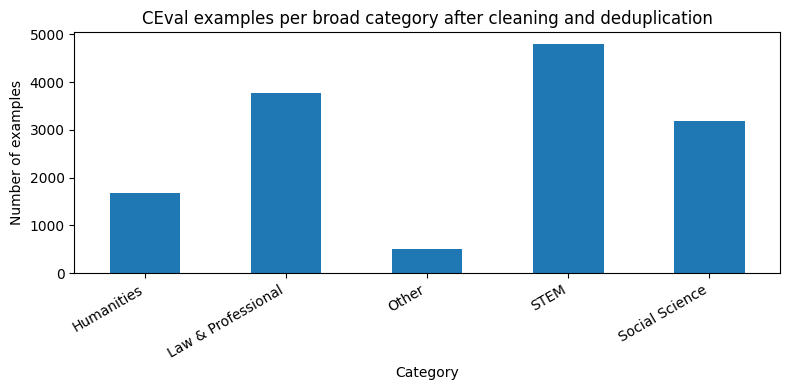

In [45]:
plt.figure(figsize=(8, 4))
df["category"].value_counts().sort_index().plot(kind="bar")
plt.title("CEval examples per broad category after cleaning and deduplication")
plt.xlabel("Category")
plt.ylabel("Number of examples")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

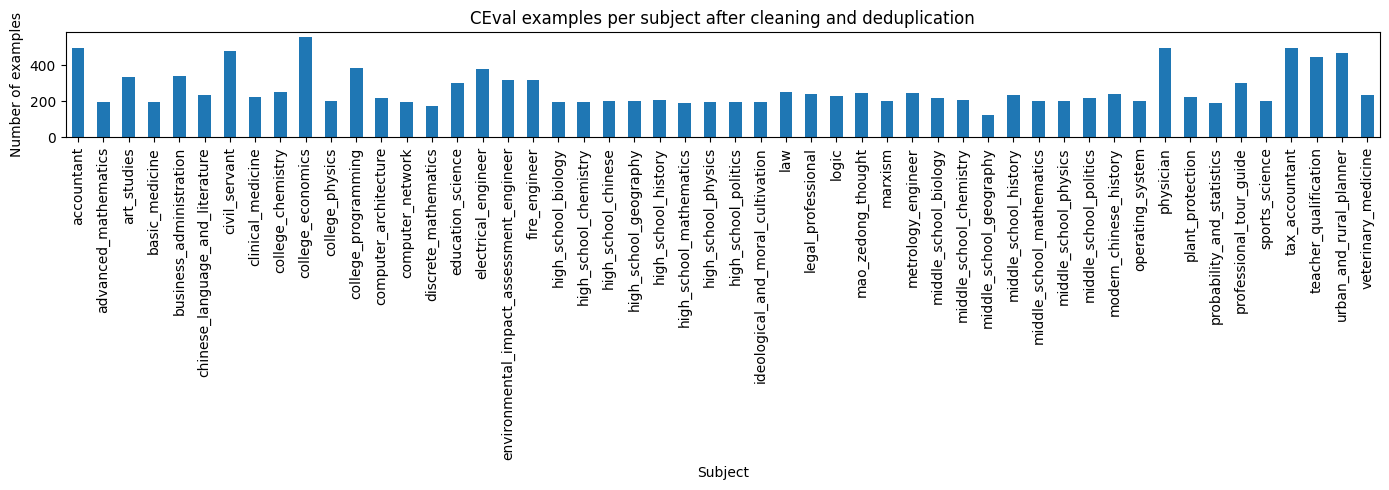

In [46]:
plt.figure(figsize=(14, 5))
df["subject"].value_counts().sort_index().plot(kind="bar")
plt.title("CEval examples per subject after cleaning and deduplication")
plt.xlabel("Subject")
plt.ylabel("Number of examples")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [47]:
for category in sorted(df["category"].unique()):
    subjects_in_category = sorted(df.loc[df["category"] == category, "subject"].unique())
    print(f"\n{category} ({len(subjects_in_category)} subjects)")

    for subject in subjects_in_category:
        n = int((df["subject"] == subject).sum())
        print(f"  - {subject}: {n}")


Humanities (7 subjects)
  - art_studies: 336
  - chinese_language_and_literature: 237
  - high_school_chinese: 202
  - high_school_history: 207
  - logic: 231
  - middle_school_history: 234
  - modern_chinese_history: 240

Law & Professional (11 subjects)
  - accountant: 497
  - basic_medicine: 199
  - business_administration: 339
  - clinical_medicine: 227
  - fire_engineer: 318
  - law: 250
  - legal_professional: 243
  - physician: 497
  - tax_accountant: 497
  - urban_and_rural_planner: 469
  - veterinary_medicine: 238

Other (2 subjects)
  - professional_tour_guide: 300
  - sports_science: 204

STEM (21 subjects)
  - advanced_mathematics: 197
  - college_chemistry: 253
  - college_physics: 200
  - college_programming: 384
  - computer_architecture: 219
  - computer_network: 195
  - discrete_mathematics: 174
  - electrical_engineer: 381
  - environmental_impact_assessment_engineer: 317
  - high_school_biology: 199
  - high_school_chemistry: 196
  - high_school_mathematics: 189
  -

In [51]:
def make_prompt(row):
    return (
        f"{row['question']}\n\n"
        f"A) {row['A']}\n"
        f"B) {row['B']}\n"
        f"C) {row['C']}\n"
        f"D) {row['D']}"
    )


def safe_id_part(text):
    return (
        str(text)
        .strip()
        .replace("/", "_")
        .replace("\\", "_")
        .replace(" ", "_")
        .replace("-", "_")
        .replace(":", "_")
    )


def make_record(row, idx):
    subject = safe_id_part(row["subject"])
    source_split = safe_id_part(row["source_split"])
    source_idx = int(row["source_idx"])

    return {
        "id": f"ceval_chinese_all_{subject}_{source_split}_{source_idx}",
        "dataset": "ceval",
        "language": "chinese",
        "split": "all",
        "task_type": "mcq",
        "prompt": make_prompt(row),
        "answer": row["answer"],
        "metadata": {
            "subject": row["subject"],
            "category": row["category"],
            "regionality": row["regionality"],
            "source_split": row["source_split"],
            "source_idx": source_idx,
            "explanation": row.get("explanation", ""),
        }
    }

In [54]:
records = []
for idx, row in df.reset_index(drop=True).iterrows():
    records.append(make_record(row, idx))

print(f"Created records: {len(records)}")
records[0]

Created records: 13945


{'id': 'ceval_chinese_all_accountant_dev_0',
 'dataset': 'ceval',
 'language': 'chinese',
 'split': 'all',
 'task_type': 'mcq',
 'prompt': '甲公司是国内一家上市公司。甲公司对其各子公司实行全面预算管理，并通常使用增量预算方式进行战略控制，子公司预算需要经甲公司预算管理委员会批准后执行。2015年10月，甲公司投资了一个新的项目乙(子公司)。2015年11月，甲公司启动2016年度预算编制工作，此时甲公司应要求乙公司编制____。\n\nA) 增量预算\nB) 零基预算\nC) 固定预算\nD) 弹性预算',
 'answer': 'B',
 'metadata': {'subject': 'accountant',
  'category': 'Law & Professional',
  'regionality': 'regional_implicit',
  'source_split': 'dev',
  'source_idx': 0,
  'explanation': '1. 乙公司属于甲公司全新的子公司，在启动2016年度预算编制工作时没有可以参考的基数，预算编制者必须根据自己的经验和判断，加上对周围环境变化的预期来做预算。因此，乙公司应编制零基预算。'}}

In [58]:
def validate_record(record):
    expected_keys = {
        "id",
        "dataset",
        "language",
        "split",
        "task_type",
        "prompt",
        "answer",
        "metadata",
    }

    assert set(record.keys()) == expected_keys

    assert isinstance(record["id"], str)
    assert record["id"].startswith("ceval_chinese_all_")
    assert record["dataset"] == "ceval"
    assert record["language"] == "chinese"
    assert record["split"] == "all"
    assert record["task_type"] == "mcq"
    assert record["answer"] in {"A", "B", "C", "D"}

    prompt = record["prompt"]
    assert isinstance(prompt, str)
    assert prompt.strip()
    assert "\n\nA) " in prompt
    assert "\nB) " in prompt
    assert "\nC) " in prompt
    assert "\nD) " in prompt

    metadata = record["metadata"]
    assert set(metadata.keys()) == {
        "subject",
        "category",
        "regionality",
        "source_split",
        "source_idx",
        "explanation",
    }

    assert metadata["category"] in {
        "STEM",
        "Humanities",
        "Social Science",
        "Law & Professional",
        "Other",
    }
    assert metadata["regionality"] in {
        "regional",
        "regional_implicit",
        "region_agnostic",
    }
    assert metadata["source_split"] in {"dev", "val", "test"}
    assert isinstance(metadata["source_idx"], int)


for record in records:
    validate_record(record)

print("All records validated successfully.")

All records validated successfully.


# Save

In [60]:
def write_jsonl(records, path):
    with path.open("w", encoding="utf-8") as f:
        for record in records:
            f.write(json.dumps(record, ensure_ascii=False) + "\n")

In [66]:
# all subsets together
write_jsonl(records, ALL_PATH)
print(f"Saved {len(records)} CEval records to:")
print(ALL_PATH)

# regional splits
REGIONALITY_TO_PATH = {
    "regional": OUTPUT_DIR / "ceval_chinese_regional.jsonl",
    "regional_implicit": OUTPUT_DIR / "ceval_chinese_regional_implicit.jsonl",
    "region_agnostic": OUTPUT_DIR / "ceval_chinese_region_agnostic.jsonl",
}

for regionality, path in REGIONALITY_TO_PATH.items():
    subset_records = [
        record for record in records
        if record["metadata"]["regionality"] == regionality
    ]
    write_jsonl(subset_records, path)
    print(f"Saved {len(subset_records)} records to:")
    print(path)

Saved 13945 CEval records to:
/scratch/workspace/emma/standard-project-m2-mystery-machine/multilingual/data/sft/preprocessed/ceval_chinese_all.jsonl
Saved 3347 records to:
/scratch/workspace/emma/standard-project-m2-mystery-machine/multilingual/data/sft/preprocessed/ceval_chinese_regional.jsonl
Saved 6110 records to:
/scratch/workspace/emma/standard-project-m2-mystery-machine/multilingual/data/sft/preprocessed/ceval_chinese_regional_implicit.jsonl
Saved 4488 records to:
/scratch/workspace/emma/standard-project-m2-mystery-machine/multilingual/data/sft/preprocessed/ceval_chinese_region_agnostic.jsonl


In [67]:
for regionality, path in REGIONALITY_TO_PATH.items():
    with path.open("r", encoding="utf-8") as f:
        n_lines = sum(1 for _ in f)

    expected = sum(
        1 for record in records
        if record["metadata"]["regionality"] == regionality
    )

    print(regionality, n_lines, expected)
    assert n_lines == expected

regional 3347 3347
regional_implicit 6110 6110
region_agnostic 4488 4488


In [70]:
df.head(1)

,question,A,B,C,D,answer,explanation,subject,category,source_split,source_idx,n_examples_in_subject_split,regionality
0,甲公司是国内一家上市公司。甲公司对其各子公司实行全面预算管理，并通常使用增量预算方式进行战略...,增量预算,零基预算,固定预算,弹性预算,B,1. 乙公司属于甲公司全新的子公司，在启动2016年度预算编制工作时没有可以参考的基数，预算...,accountant,Law & Professional,dev,0,5,regional_implicit
